<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/12-supervised-learning/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 12: Supervised Learning in Depth

Part 1 used supervised learning everywhere: k-nearest neighbours, naive Bayes, logistic regression, small neural networks. This module, the first of Part 2, slows down and looks at the ideas underneath all of them:

- what a linear model really is, and how far good **features** can stretch it
- how to **measure** a regression model, and what each number hides
- why models fail in two opposite ways, **bias** and **variance**, and how to tell which one you have
- **regularisation**: the main tool for controlling variance, and why it's essential once you have many features
- **logistic regression** in more depth: decision boundaries, several classes, and regularisation for classifiers

Linear models are worth this much attention. They're fast, they're easy to explain, they work well with little data, and they're still a strong baseline in industry. And the ideas here, bias and variance, regularisation and learning curves, apply to every model in the rest of the course, including deep neural networks.

**Contents**

1. The supervised learning setup
2. Linear regression, three ways
3. Measuring a regression model
4. Features make linear models flexible
5. Bias and variance
6. Regularisation: ridge and lasso
7. Learning curves: diagnosing a model
8. Logistic regression in depth
9. A checklist for supervised problems

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import load_diabetes

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/05-files-and-data/data/penguins.csv"
local = Path("data/penguins.csv")
penguins = pd.read_csv(local if local.exists() else DATA_URL)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. The supervised learning setup

Every supervised problem has the same parts. It helps to have names for them:

| symbol | name | example |
|---|---|---|
| `x` | the **features** of one example | a patient's age, BMI and blood pressure |
| `y` | the **target** (label) | disease progression a year later |
| `X`, `y` | the training data: `n` examples | 442 patients |
| `f` | the **model**: a function from `x` to a prediction `ŷ` | `ŷ = w · x + b` |
| `L(y, ŷ)` | the **loss** for one prediction | squared error `(y - ŷ)²` |

**Training** means choosing the model's parameters to make the average loss on the training data small. But that's not the real goal. The real goal is a small loss on **new** data from the same source, which we can only estimate, with held-out data or cross-validation (Module 11).

The gap between those two, how well a model does on the data it saw versus data it didn't, is what most of this module is about.

The lesson uses a dataset that ships with scikit-learn: **442 diabetes patients**, with ten baseline measurements each (age, sex, BMI, average blood pressure and six blood serum measurements, called `s1` to `s6`), and a number measuring how much the disease progressed one year later. The features have already been centred and scaled by the dataset's authors.

In [3]:
diabetes = load_diabetes(as_frame=True)
X_d, y_d = diabetes.data, diabetes.target
print(X_d.shape)
X_d.head()

(442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## 2. Linear regression, three ways

A linear regression model predicts with a weighted sum of the features:

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_d x_d + b = \mathbf{x} \cdot \mathbf{w} + b$$

The **least squares** fit chooses `w` and `b` to minimise the mean squared error. For this loss there's an exact answer, so there are three ways to get it, and they should agree:

1. **Solve the normal equations.** Setting the gradient of the squared error to zero gives `(XᵀX) w = Xᵀy`, a linear system (with a column of ones in `X` for the bias).
2. **Least squares directly**, with `np.linalg.lstsq`, which is more numerically careful.
3. **scikit-learn's `LinearRegression`.**

In [4]:
from sklearn.linear_model import LinearRegression

A = np.column_stack([X_d.to_numpy(), np.ones(len(X_d))])        # add a column of ones for the bias
y_arr = y_d.to_numpy()

normal_eq = np.linalg.solve(A.T @ A, A.T @ y_arr)
least_sq = np.linalg.lstsq(A, y_arr, rcond=None)[0]
library = LinearRegression().fit(X_d, y_d)
sk = np.append(library.coef_, library.intercept_)

print("largest difference, normal equations vs lstsq: ", f"{np.abs(normal_eq - least_sq).max():.1e}")
print("largest difference, lstsq vs scikit-learn:     ", f"{np.abs(least_sq - sk).max():.1e}")
pd.Series(sk, index=list(X_d.columns) + ["bias"]).round(1)

largest difference, normal equations vs lstsq:  1.0e-11
largest difference, lstsq vs scikit-learn:      5.8e-12


age     -10.0
sex    -239.8
bmi     519.8
bp      324.4
s1     -792.2
s2      476.7
s3      101.0
s4      177.1
s5      751.3
s6       67.6
bias    152.1
dtype: float64

All three agree. In practice you'd use `LinearRegression` (or `lstsq`); the normal equations are worth knowing because the formula explains what goes wrong next.

**Reading the weights.** Each weight is the change in the prediction for a one-unit increase in that feature, **with every other feature held fixed**. BMI (`bmi`) and `s5` have large positive weights: higher values go with faster progression.

But look at `s1` and `s2`: two huge weights with **opposite signs**. Taken at face value, raising `s1` sharply lowers progression and raising `s2` sharply raises it. That's suspicious, and here's why:

In [5]:
print(X_d[["s1", "s2", "s3", "s4"]].corr().round(2))

      s1    s2    s3    s4
s1  1.00  0.90  0.05  0.54
s2  0.90  1.00 -0.20  0.66
s3  0.05 -0.20  1.00 -0.74
s4  0.54  0.66 -0.74  1.00


`s1` and `s2` (two cholesterol measurements) are correlated at 0.9. When two features carry nearly the same information, "hold one fixed and change the other" describes something that almost never happens in the data, and the least squares fit can trade one off against the other: a big positive weight on one and a big negative weight on the other fit the data almost as well as two small weights. This is called **multicollinearity**.

The formula shows the cause. Least squares needs `(XᵀX)⁻¹`, and when columns are nearly copies of each other, `XᵀX` is close to a matrix that can't be inverted. Tiny changes in the data then cause big swings in the weights. The predictions can still be fine, but the individual weights stop meaning much. Section 6 fixes this.

## 3. Measuring a regression model

To measure fairly, use predictions for data the model didn't train on. `cross_val_predict` gives every patient a prediction from a model trained on the other folds:

In [6]:
from sklearn.model_selection import KFold, cross_val_predict

cv = KFold(n_splits=10, shuffle=True, random_state=0)
pred_d = cross_val_predict(LinearRegression(), X_d, y_d, cv=cv)
errors = y_d - pred_d

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))
r2 = 1 - np.sum(errors ** 2) / np.sum((y_d - y_d.mean()) ** 2)
baseline_rmse = np.sqrt(np.mean((y_d - y_d.mean()) ** 2))

print(f"MAE  {mae:6.1f}   (mean absolute error)")
print(f"RMSE {rmse:6.1f}   (root mean squared error)")
print(f"R²   {r2:6.3f}")
print(f"baseline RMSE, always predicting the mean: {baseline_rmse:.1f}")

MAE    44.3   (mean absolute error)
RMSE   54.7   (root mean squared error)
R²    0.496
baseline RMSE, always predicting the mean: 77.0


The three standard metrics, and what each one is for:

- **MAE**, the mean absolute error, is the average size of a mistake, in the target's own units. It's the easiest to explain: "on average, the prediction is off by about 44".
- **RMSE**, the root mean squared error, squares the errors before averaging, so **large mistakes count much more**. It's also in the target's units, and always at least as big as the MAE. The bigger the gap between them, the more the errors are dominated by a few large misses.
- **R²** compares the model with the simplest possible baseline, always predicting the average: `R² = 1 - (model's squared error) / (baseline's squared error)`. 1 is perfect, 0 is no better than the average, and on new data it can be **negative**, meaning worse than just predicting the average.

Here the model explains about half of the variation (R² ≈ 0.50). That's typical for medical outcomes, where much of what happens depends on things not measured. Whether it's "good" depends on the use: as a screening aid it might be useful; as an individual prognosis, the typical error of 44 to 55 on a scale where most values fall between 25 and 346 is large.

MAE and RMSE react very differently to a few big mistakes:

In [7]:
typical = np.array([10.0, -12.0, 8.0, -9.0, 11.0, -10.0, 9.0, -8.0])
one_bad = np.append(typical[:-1], 80.0)          # one prediction badly wrong
for name, e in [("typical errors", typical), ("one big miss", one_bad)]:
    print(f"{name:<15} MAE {np.mean(np.abs(e)):5.1f}   RMSE {np.sqrt(np.mean(e ** 2)):5.1f}")

typical errors  MAE   9.6   RMSE   9.7
one big miss    MAE  18.6   RMSE  29.8


One bad prediction out of eight barely doubles the MAE but nearly triples the RMSE. Neither is "right": RMSE suits problems where big errors are disproportionately costly, MAE suits problems where every unit of error costs the same. (A fourth metric you'll see, **MAPE**, the mean absolute **percentage** error, is easy to explain but breaks down when true values are near zero, since dividing by a tiny number makes any error look enormous.)

A single number can't show **how** a model is wrong. A **residual plot**, errors against predictions, can:

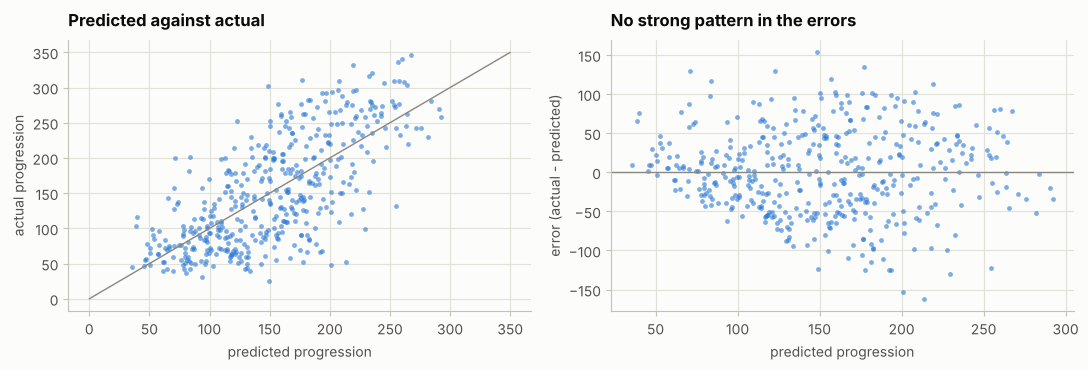

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(pred_d, y_d, s=12, color=PALETTE[0], alpha=0.6)
lims = [0, 350]
axes[0].plot(lims, lims, color=MUTED, linewidth=1)
axes[0].set_xlabel("predicted progression")
axes[0].set_ylabel("actual progression")
axes[0].set_title("Predicted against actual")
axes[1].scatter(pred_d, errors, s=12, color=PALETTE[0], alpha=0.6)
axes[1].axhline(0, color=MUTED, linewidth=1)
axes[1].set_xlabel("predicted progression")
axes[1].set_ylabel("error (actual - predicted)")
axes[1].set_title("No strong pattern in the errors")
fig.tight_layout()
plt.show()

What to look for:

- **On the right**, errors against predictions. In a well-specified model they form a featureless band around zero, and here they mostly do: no curve, and roughly the same spread everywhere. A curve would mean the model misses a non-linear effect (section 4). A band that **widens** as predictions grow (called **heteroscedasticity**) would mean errors are proportional to the size of the value, which usually calls for modelling the logarithm of the target. You'll meet that pattern in the mini project.
- **On the left**, predictions against actual values. The predictions are **squeezed**: actual progression runs from 25 to 346, predictions from about 40 to 290. Patients with extreme outcomes are pulled towards the middle. That's what a model does when its features explain only half the variation: it hedges towards the average.

## 4. Features make linear models flexible

"Linear" means linear in the **weights**, not in the original inputs. If you add new columns that are functions of the inputs, such as squares, products and logarithms, the model is still linear regression, fitted the same way, but it can draw curves.

### Polynomial features

Here's data that follows a curve. A straight line can't fit it, but adding `x²` as a second column lets the same least squares fit a parabola:

with x and x² as features: weights [-1.04  0.51] bias -0.02


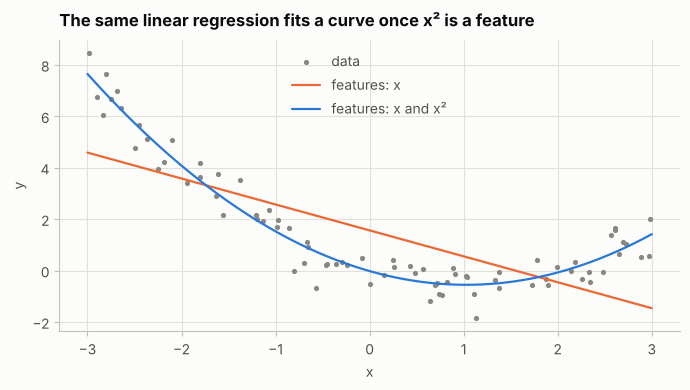

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, StandardScaler

rng = np.random.default_rng(0)
x_c = rng.uniform(-3, 3, 80)
y_c = 0.5 * x_c ** 2 - x_c + rng.normal(0, 0.6, 80)
grid = np.linspace(-3, 3, 200)

straight = LinearRegression().fit(x_c[:, None], y_c)
squared = LinearRegression().fit(np.column_stack([x_c, x_c ** 2]), y_c)
print("with x and x² as features: weights", squared.coef_.round(2), "bias", round(squared.intercept_, 2))

fig, ax = plt.subplots()
ax.scatter(x_c, y_c, color=MUTED, s=14, label="data")
ax.plot(grid, straight.predict(grid[:, None]), color=PALETTE[1], label="features: x")
ax.plot(grid, squared.predict(np.column_stack([grid, grid ** 2])), color=PALETTE[0], label="features: x and x²")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("The same linear regression fits a curve once x² is a feature")
ax.legend(loc="upper center")
fig.tight_layout()
plt.show()

The fitted weights, about -1 for `x` and 0.5 for `x²`, recover the true curve `0.5x² - x`. `PolynomialFeatures` builds these columns automatically, including **interactions** like `x₁·x₂`, which let the effect of one feature depend on another (for example, the effect of extra rooms on a house's price might depend on its location).

### Other useful transformations

- **Logarithms** for features that are positive and skewed, with a long tail of large values: incomes, populations, counts. The log pulls in the tail, so a few huge values don't dominate the fit, and it turns multiplicative effects ("10% more income") into additive ones, which a linear model handles well.
- **One-hot encoding** for categories (Modules 7 and 11).
- **Ratios** that mean more than their parts: rooms **per household** says more about a house than the total rooms in a district.
- **Splines**: smooth, flexible curves built from pieces of polynomials joined at points called **knots**. Unlike a high-degree polynomial, a spline stays well-behaved at the edges of the data.

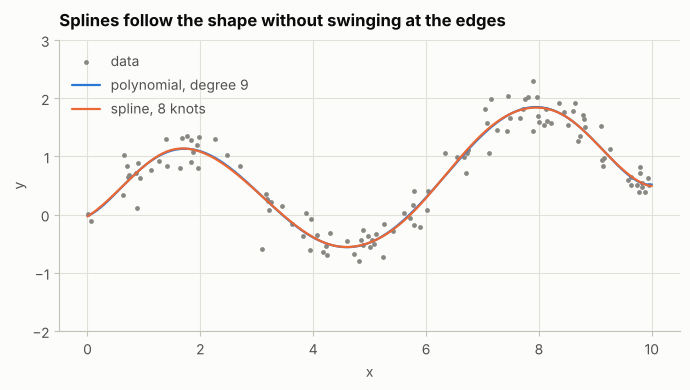

In [10]:
x_s = np.sort(rng.uniform(0, 10, 120))
y_s = np.sin(x_s) + 0.1 * x_s + rng.normal(0, 0.25, 120)
grid_s = np.linspace(0, 10, 300)[:, None]

fig, ax = plt.subplots()
ax.scatter(x_s, y_s, color=MUTED, s=12, label="data")
for (name, model), colour in zip({
    "polynomial, degree 9": make_pipeline(PolynomialFeatures(9), StandardScaler(), LinearRegression()),
    "spline, 8 knots": make_pipeline(SplineTransformer(n_knots=8, degree=3), LinearRegression()),
}.items(), PALETTE):
    model.fit(x_s[:, None], y_s)
    ax.plot(grid_s, model.predict(grid_s), color=colour, label=name)
ax.set_ylim(-2, 3)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Splines follow the shape without swinging at the edges")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

Both fit the middle of the data. The degree-9 polynomial turns sharply at the right edge, where the data is thinnest; the spline stays calm. Splines are the better default when you need a flexible curve for one feature.

**Feature engineering** like this is where domain knowledge enters a model. For linear models it often matters more than anything else you do.

## 5. Bias and variance

Flexible features let a model fit more shapes. Too much flexibility, though, and it starts fitting the noise (Start Here, section 5). The **bias-variance decomposition** makes this precise.

Imagine collecting many different training sets from the same source, fitting the same kind of model to each, and looking at its predictions at one point:

- **Bias** is how far the **average** prediction is from the truth. A straight line fitted to a curve is wrong in the same way every time: high bias.
- **Variance** is how much the predictions **jump around** from one training set to another. A very flexible model chases the particular noise in each training set: high variance.

For squared error, the expected error on new data splits exactly into three parts:

$$\text{expected error} = \text{bias}^2 + \text{variance} + \text{noise}$$

The noise is the randomness in `y` itself, which no model can remove. We can measure the other two by simulation: draw 300 training sets of 25 points from a known curve, fit polynomials of each degree, and compare the predictions.

In [11]:
def truth(x):
    return np.sin(1.5 * x)


NOISE_SD = 0.3
x_eval = np.linspace(0.2, 3.8, 60)
degrees = range(1, 9)
rng = np.random.default_rng(1)

predictions = {d: [] for d in degrees}
for _ in range(300):
    x_tr = rng.uniform(0, 4, 25)
    y_tr = truth(x_tr) + rng.normal(0, NOISE_SD, 25)
    for d in degrees:
        fit = np.polynomial.Polynomial.fit(x_tr, y_tr, d)
        predictions[d].append(fit(x_eval))

rows = []
for d in degrees:
    p = np.array(predictions[d])                      # shape (300 training sets, 60 points)
    bias_sq = np.mean((p.mean(axis=0) - truth(x_eval)) ** 2)
    variance = np.mean(p.var(axis=0))
    rows.append({"degree": d, "bias²": bias_sq, "variance": variance, "total": bias_sq + variance + NOISE_SD ** 2})
bv = pd.DataFrame(rows).set_index("degree")
bv.round(4)

,bias²,variance,total
degree,,,
1,0.1335,0.0218,0.2453
2,0.1204,0.0453,0.2558
3,0.0026,0.0176,0.1102
4,0.0018,0.0230,0.1147
5,0.0002,0.0398,0.1300
6,0.0003,0.1850,0.2753
7,0.0028,0.9072,1.0000
8,0.0005,1.8693,1.9598


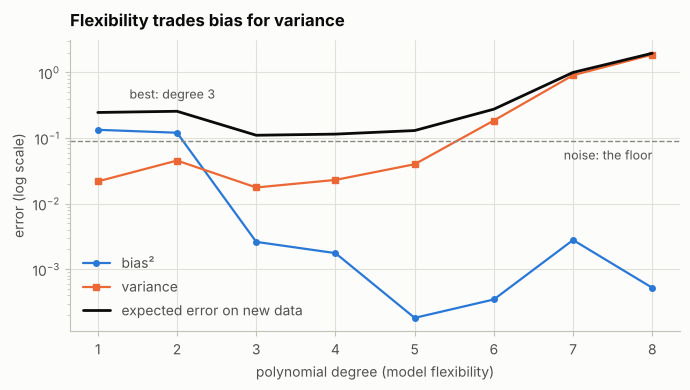

In [12]:
fig, ax = plt.subplots()
ax.plot(bv.index, bv["bias²"], color=PALETTE[0], marker="o", markersize=4, label="bias²")
ax.plot(bv.index, bv["variance"], color=PALETTE[1], marker="s", markersize=4, label="variance")
ax.plot(bv.index, bv["total"], color=INK, linewidth=2, label="expected error on new data")
ax.axhline(NOISE_SD ** 2, color=MUTED, linewidth=1, linestyle="--")
ax.text(8, NOISE_SD ** 2 * 0.8, "noise: the floor", color=INK_2, ha="right", va="top", fontsize=9)
best = int(bv["total"].idxmin())
ax.annotate(f"best: degree {best}", xy=(best, bv.loc[best, "total"]), xytext=(best - 1.6, 0.4),
            arrowprops={"arrowstyle": "-", "color": MUTED}, color=INK_2, fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("polynomial degree (model flexibility)")
ax.set_ylabel("error (log scale)")
ax.set_title("Flexibility trades bias for variance")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

The picture behind almost every modelling decision:

- At low degree, **bias dominates**: the model is too rigid to follow the curve, and no amount of data fixes that.
- As flexibility grows, bias falls quickly, but **variance rises**, slowly at first and then sharply: with 25 points, a degree-8 polynomial bends to fit each training set's noise, and its variance is about 100 times the cubic's. (Go beyond degree 8 and the variance explodes into the hundreds, which is why the chart stops there.)
- The **total error** has a minimum in between. That's the model to want.

Two things move the curves. **More data** lowers variance, because each fit is less at the mercy of a few noisy points; with 250 points instead of 25, high degrees would be far less harmful. **Regularisation**, next, lowers variance directly, without throwing away flexibility.

## 6. Regularisation: ridge and lasso

Regularisation adds a **penalty on the size of the weights** to the loss. The model now balances fitting the data against keeping its weights small, and large weights have to earn their place.

### Ridge regression (L2)

Ridge adds the sum of squared weights, times a strength `α` (alpha):

$$\text{loss} = \sum_i (y_i - \hat{y}_i)^2 + \alpha \sum_j w_j^2$$

The exact solution is the normal equations with `α` added to the diagonal:

$$\mathbf{w} = (X^\top X + \alpha I)^{-1} X^\top \mathbf{y}$$

That small change is exactly what fixes the multicollinearity problem from section 2: adding `α` to the diagonal keeps the matrix comfortably invertible, however similar the columns are. By convention the bias isn't penalised (shrinking it would just move every prediction towards zero), which is handled by centring the data first.

In [13]:
from sklearn.linear_model import Lasso, Ridge


def ridge_by_hand(X, y, alpha):
    X_mean, y_mean = X.mean(axis=0), y.mean()
    Xc, yc = X - X_mean, y - y_mean                     # centring removes the bias from the problem
    w = np.linalg.solve(Xc.T @ Xc + alpha * np.eye(X.shape[1]), Xc.T @ yc)
    return w, y_mean - X_mean @ w


Xs = StandardScaler().fit_transform(X_d)                # penalties need features on one scale
w_hand, b_hand = ridge_by_hand(Xs, y_arr, alpha=10.0)
sk_ridge = Ridge(alpha=10.0).fit(Xs, y_arr)
print("largest difference from scikit-learn:", f"{max(np.abs(w_hand - sk_ridge.coef_).max(), abs(b_hand - sk_ridge.intercept_)):.1e}")

largest difference from scikit-learn: 1.7e-14


**Standardise before regularising.** The penalty treats all weights alike, but a weight's size depends on its feature's units: body mass in grams needs a tiny weight, in kilograms a weight 1,000 times bigger. Without standardising, the penalty would punish features for their units. In a pipeline, a `StandardScaler` before the model takes care of it.

### Lasso (L1)

The lasso penalises the sum of **absolute** weights instead:

$$\text{loss} = \frac{1}{2n}\sum_i (y_i - \hat{y}_i)^2 + \alpha \sum_j |w_j|$$

That small change has a big consequence: the lasso sets some weights **exactly to zero**, removing those features from the model. It does feature selection as part of fitting. (There's no exact formula; it's fitted by an iterative method called coordinate descent, which you'll write in the exercises.)

Watch what happens to the diabetes weights as `α` grows, for each penalty:

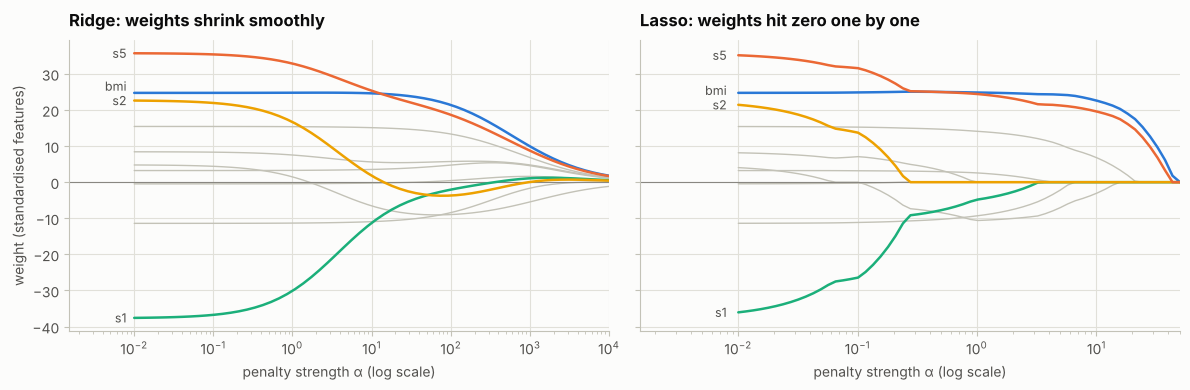

In [14]:
alphas = np.logspace(-2, 4, 60)
ridge_path = np.array([Ridge(alpha=a).fit(Xs, y_arr).coef_ for a in alphas])
lasso_alphas = np.logspace(-2, 1.7, 60)
lasso_path = np.array([Lasso(alpha=a, max_iter=50_000).fit(Xs, y_arr).coef_ for a in lasso_alphas])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
names = list(X_d.columns)
highlight = {"bmi": PALETTE[0], "s5": PALETTE[1], "s1": PALETTE[2], "s2": PALETTE[3]}
for ax, path, a, title in [(axes[0], ridge_path, alphas, "Ridge: weights shrink smoothly"),
                           (axes[1], lasso_path, lasso_alphas, "Lasso: weights hit zero one by one")]:
    label_y = {}
    for j, name in enumerate(names):
        colour = highlight.get(name, AXIS)
        ax.plot(a, path[:, j], color=colour, linewidth=1.8 if name in highlight else 1, zorder=3 if name in highlight else 2)
        if name in highlight:
            label_y[name] = path[0, j]
    placed = []
    for name, y_pos in sorted(label_y.items(), key=lambda kv: kv[1]):     # nudge labels apart so they don't overlap
        if placed and y_pos - placed[-1] < 4:
            y_pos = placed[-1] + 4
        placed.append(y_pos)
        ax.text(a[0] * 0.8, y_pos, name, color=INK_2, fontsize=9, ha="right", va="center")
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("penalty strength α (log scale)")
    ax.set_title(title)
    ax.set_xlim(a[0] * 0.15, a[-1])
axes[0].set_ylabel("weight (standardised features)")
fig.tight_layout()
plt.show()

Read each panel from left (almost no penalty, the least squares answer) to right (strong penalty):

- **Ridge** shrinks every weight smoothly towards zero. The wildly opposed `s1` and `s2` weights collapse towards each other within a small range of `α`: the penalty makes the "big positive, big negative" trick too expensive. No weight becomes exactly zero.
- **The lasso** drives weights to exactly zero, one at a time. `s2` is among the first to go (once `s1` carries the shared information, `s2` adds little), and the last features standing are `bmi` and `s5`, the two most useful predictors. Lasso is a natural choice when you suspect only a few features matter and want a simpler model.
- **Elastic net** mixes the two penalties, getting the lasso's selection with some of ridge's stability when features are correlated.

### Choosing α

`α` is a hyperparameter, chosen by cross-validation. Regularisation matters most when there are **many features** relative to the data. To see that, give the diabetes model all the squares and pairwise products of its ten features, 65 features for 442 patients, and compare penalty strengths:

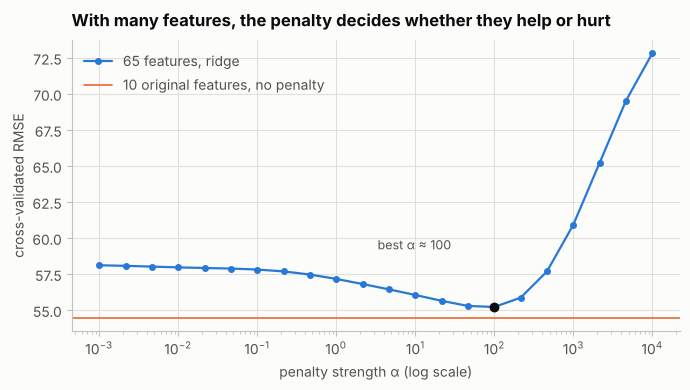

65 features, no penalty: RMSE 58.2
65 features, best ridge: RMSE 55.2 at α ≈ 100
10 features, no penalty: RMSE 54.5


In [15]:
from sklearn.model_selection import cross_val_score

poly_alphas = np.logspace(-3, 4, 22)
poly_scores = []
for a in poly_alphas:
    model = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge(alpha=a))
    poly_scores.append(-cross_val_score(model, X_d, y_d, cv=cv, scoring="neg_root_mean_squared_error").mean())
poly_scores = np.array(poly_scores)
plain = -cross_val_score(make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
                         X_d, y_d, cv=cv, scoring="neg_root_mean_squared_error").mean()
linear_only = -cross_val_score(LinearRegression(), X_d, y_d, cv=cv, scoring="neg_root_mean_squared_error").mean()

fig, ax = plt.subplots()
ax.plot(poly_alphas, poly_scores, color=PALETTE[0], marker="o", markersize=4, label="65 features, ridge")
ax.axhline(linear_only, color=PALETTE[1], linewidth=1.2, label="10 original features, no penalty")
best_alpha = poly_alphas[np.argmin(poly_scores)]
ax.scatter([best_alpha], [poly_scores.min()], color=INK, s=50, zorder=4)
ax.annotate(f"best α ≈ {best_alpha:.0f}", xy=(best_alpha, poly_scores.min()), xytext=(best_alpha / 30, poly_scores.min() + 4),
            arrowprops={"arrowstyle": "-", "color": MUTED}, color=INK_2, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("penalty strength α (log scale)")
ax.set_ylabel("cross-validated RMSE")
ax.set_title("With many features, the penalty decides whether they help or hurt")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
print(f"65 features, no penalty: RMSE {plain:.1f}")
print(f"65 features, best ridge: RMSE {poly_scores.min():.1f} at α ≈ {best_alpha:.0f}")
print(f"10 features, no penalty: RMSE {linear_only:.1f}")

The shape is the bias-variance curve again, drawn against the penalty instead of the degree:

- At the left, with almost no penalty, 65 features overfit: the cross-validated error is **worse** than the plain 10-feature model's.
- At the right, the penalty is so strong that it flattens every weight: high bias, error rises again.
- In the middle, the penalty brings the 65-feature model back to almost exactly where the plain 10-feature model is, but **not past it**.

That last point is an honest and common result. The squares and products of these measurements don't carry useful extra information about diabetes progression, so the best the penalty can do is stop them hurting. Regularisation can't create signal that isn't there; it only stops a model from mistaking noise for signal. When there **is** extra signal in many features, as in the mini project, the same tool turns them into a real gain.

`RidgeCV` and `LassoCV` do this search for you, efficiently, and pick the best `α` by cross-validation.

## 7. Learning curves: diagnosing a model

When a model disappoints, the useful question is **why**: too much bias, or too much variance? The answers call for opposite fixes, so guessing wrong wastes effort.

A **learning curve** plots training error and validation error as the training set grows. Here are two models on the same kind of data, a straight line and a very flexible polynomial:

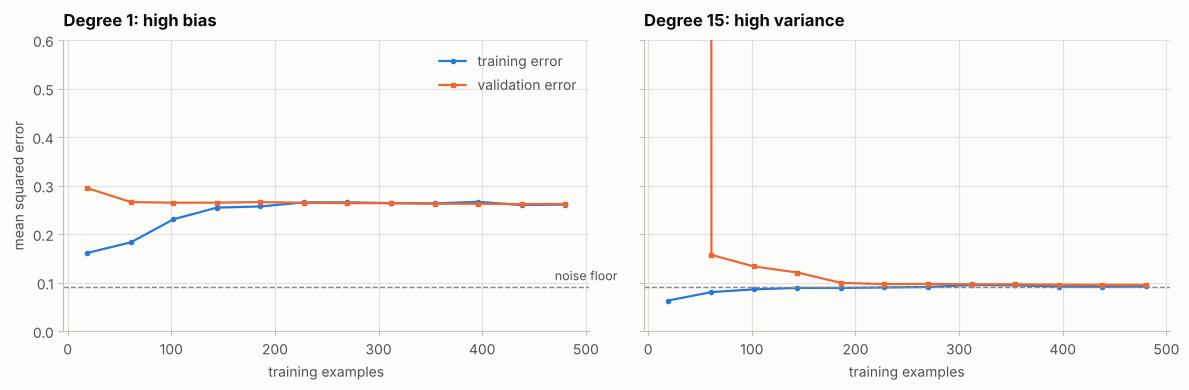

In [16]:
from sklearn.model_selection import learning_curve

rng = np.random.default_rng(2)
x_lc = rng.uniform(0, 4, 600)
y_lc = truth(x_lc) + rng.normal(0, NOISE_SD, 600)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, model) in zip(axes, {
    "Degree 1: high bias": make_pipeline(PolynomialFeatures(1), LinearRegression()),
    "Degree 15: high variance": make_pipeline(PolynomialFeatures(15), StandardScaler(), Ridge(alpha=1e-8)),
}.items()):
    sizes, train_scores, val_scores = learning_curve(
        model, x_lc[:, None], y_lc, train_sizes=np.linspace(0.04, 1, 12), cv=KFold(5, shuffle=True, random_state=0),
        scoring="neg_mean_squared_error")
    ax.plot(sizes, -train_scores.mean(axis=1), color=PALETTE[0], marker="o", markersize=3, label="training error")
    ax.plot(sizes, -val_scores.mean(axis=1), color=PALETTE[1], marker="s", markersize=3, label="validation error")
    ax.axhline(NOISE_SD ** 2, color=MUTED, linewidth=1, linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("training examples")
    ax.set_ylim(0, 0.6)
axes[0].set_ylabel("mean squared error")
axes[0].text(470, NOISE_SD ** 2 + 0.015, "noise floor", color=INK_2, fontsize=9)
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

The two shapes to recognise:

- **High bias (left).** Training and validation error **meet quickly and stay high**, well above the noise floor. The model can't even fit the data it trains on. More data won't help; the curves are already flat.
- **High variance (right).** Training error is **low**, validation error much higher at first, and the **gap shrinks** as data grows. The model fits each training set too closely; more data steadily helps.

What to do about each:

| symptom | diagnosis | try |
|---|---|---|
| both errors high, close together | high bias (underfitting) | more or better features, a more flexible model, less regularisation |
| low training error, big gap to validation | high variance (overfitting) | more data, stronger regularisation, fewer features, a simpler model |
| both errors low, close together | a good fit | stop, and check it on the test set |

`validation_curve` makes the same kind of plot against a hyperparameter instead of the data size, like the `α` chart above.

## 8. Logistic regression in depth

Logistic regression (Modules 6, 9 and 11) is linear regression's partner for classification: a weighted sum turned into a probability by the sigmoid. Everything in this module carries over. Features make it flexible, regularisation controls it, and bias and variance trade off the same way. Three things are worth seeing more closely.

### The decision boundary is a straight line

With two features, logistic regression predicts class 1 when `w₁x₁ + w₂x₂ + b > 0`. The boundary, where the probability is exactly 0.5, is the line `w₁x₁ + w₂x₂ + b = 0`. The probability changes smoothly across it, and how quickly it changes depends on the size of the weights.

### More than two classes: softmax

For `k` classes, **multinomial logistic regression** learns one weight vector per class, computes a score for each, and turns the scores into probabilities with the **softmax** (Module 6). scikit-learn's `LogisticRegression` does this automatically when there are more than two classes. Here it is on the penguins, with just bill length and depth, at two regularisation strengths:

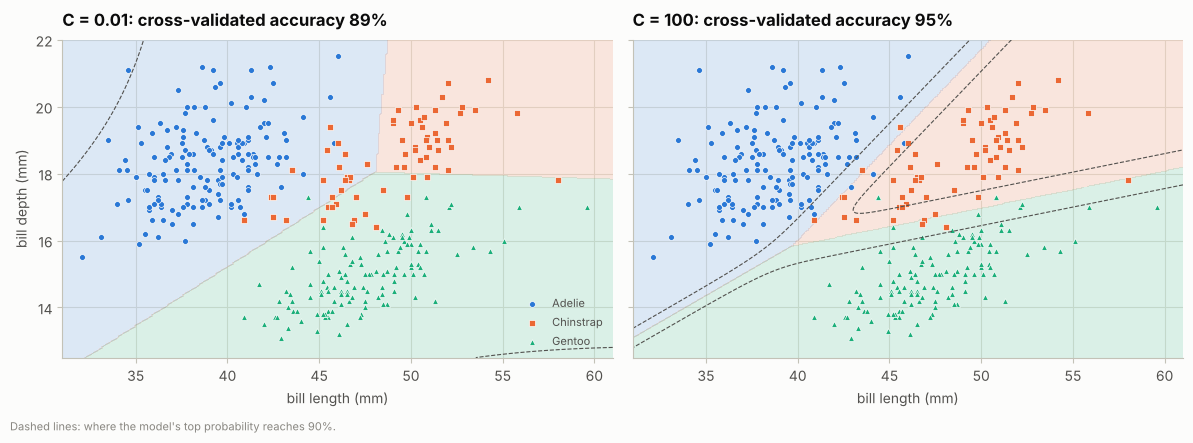

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

two = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm"])
Xp = two[["bill_length_mm", "bill_depth_mm"]].to_numpy()
yp = two["species"].to_numpy()
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
MARKERS = {"Adelie": "o", "Chinstrap": "s", "Gentoo": "^"}

gx, gy = np.meshgrid(np.linspace(31, 61, 300), np.linspace(12.5, 22, 300))
grid_points = np.column_stack([gx.ravel(), gy.ravel()])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, C in zip(axes, [0.01, 100]):
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000)).fit(Xp, yp)
    regions = np.searchsorted(SPECIES, clf.predict(grid_points)).reshape(gx.shape)
    ax.contourf(gx, gy, regions, levels=[-0.5, 0.5, 1.5, 2.5], colors=PALETTE[:3], alpha=0.15)
    confidence = clf.predict_proba(grid_points).max(axis=1).reshape(gx.shape)
    ax.contour(gx, gy, confidence, levels=[0.9], colors=[INK_2], linewidths=0.8, linestyles="--")
    for i, sp in enumerate(SPECIES):
        pts = Xp[yp == sp]
        ax.scatter(pts[:, 0], pts[:, 1], color=PALETTE[i], marker=MARKERS[sp], s=18, edgecolors=SURFACE, linewidths=0.5, label=sp)
    acc = cross_val_score(clf, Xp, yp, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
    ax.set_title(f"C = {C}: cross-validated accuracy {acc:.0%}")
    ax.set_xlabel("bill length (mm)")
axes[0].set_ylabel("bill depth (mm)")
axes[0].legend(loc="lower right", fontsize=8)
fig.text(0.01, 0.01, "Dashed lines: where the model's top probability reaches 90%.", color=MUTED, fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

Each pair of classes is separated by a straight line, so the regions are wedges meeting in the middle. Compare the two strengths (remember `C` is the **inverse** of the penalty):

- With strong regularisation (`C = 0.01`), the weights are kept small, so probabilities change slowly: the model is unsure across wide bands near the boundaries (the dashed 90% lines are far apart), and the boundaries are less well placed.
- With weak regularisation (`C = 100`), the weights are large, probabilities jump from one class to another over a short distance, and the boundaries sit where they separate the species well.

Here the weakly regularised model is clearly better in cross-validation, because two features and 342 penguins leave little room to overfit, so the penalty only gets in the way. With many features and little data, the opposite can be true. As always, cross-validation decides.

### Curved boundaries need features

Like linear regression, logistic regression can only draw curves if its features allow it. Here's a classic dataset where the classes are two interleaved half-moons:

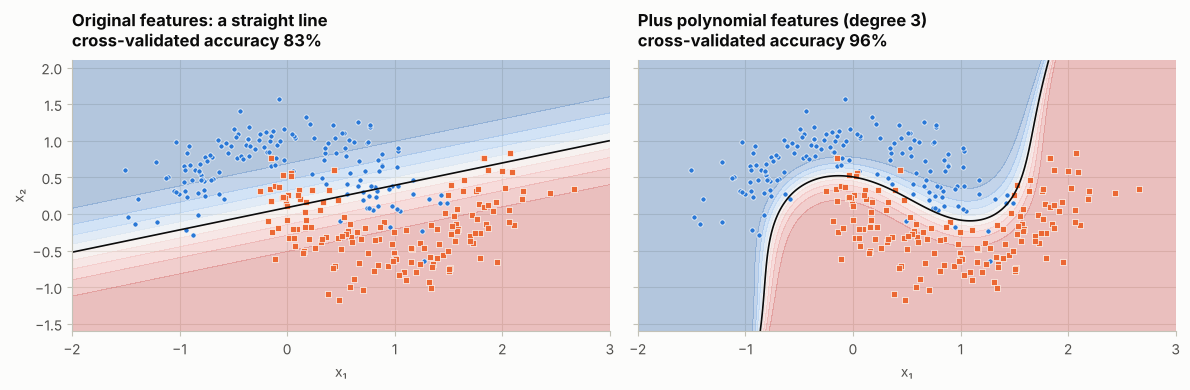

In [18]:
from sklearn.datasets import make_moons

X_m, y_m = make_moons(n_samples=300, noise=0.25, random_state=0)
gx_m, gy_m = np.meshgrid(np.linspace(-2, 3, 250), np.linspace(-1.6, 2.1, 250))
grid_m = np.column_stack([gx_m.ravel(), gy_m.ravel()])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, clf) in zip(axes, {
    "Original features: a straight line": make_pipeline(StandardScaler(), LogisticRegression()),
    "Plus polynomial features (degree 3)": make_pipeline(PolynomialFeatures(3), StandardScaler(), LogisticRegression(C=10, max_iter=5000)),
}.items()):
    cv_acc = cross_val_score(clf, X_m, y_m, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
    clf.fit(X_m, y_m)
    proba = clf.predict_proba(grid_m)[:, 1].reshape(gx_m.shape)
    ax.contourf(gx_m, gy_m, proba, levels=np.linspace(0, 1, 11), cmap=DIVERGING, alpha=0.35)
    ax.contour(gx_m, gy_m, proba, levels=[0.5], colors=[INK], linewidths=1.2)
    for cls, marker in [(0, "o"), (1, "s")]:
        ax.scatter(X_m[y_m == cls, 0], X_m[y_m == cls, 1], color=PALETTE[cls], marker=marker, s=14, edgecolors=SURFACE, linewidths=0.5)
    ax.set_title(f"{name}\ncross-validated accuracy {cv_acc:.0%}")
    ax.set_xlabel("x₁")
axes[0].set_ylabel("x₂")
fig.tight_layout()
plt.show()

With only the original two features, the best the model can do is a straight line through the middle. Adding polynomial features lets the same logistic regression bend its boundary around the moons, and the cross-validated accuracy jumps. The background shading shows the probability: the model is confident far from the boundary and unsure close to it, which is exactly what you want from a classifier's probabilities. Module 13 looks at how to check whether those probabilities can be trusted.

## 9. A checklist for supervised problems

Pulling Part 1 and this module together, a dependable order of work for any supervised problem:

1. **Define the target and the metric** from how the predictions will be used. Decide what "new data" means (later time, new places, new people), and split accordingly.
2. **Start with a baseline**: the mean for regression, the most common class for classification.
3. **Fit a simple linear model** with standardised features, inside a pipeline. It's fast and gives a reference point.
4. **Look at the errors**: residual plots, the biggest mistakes, errors by group. They suggest features.
5. **Engineer features**: logs for skewed values, ratios, interactions, splines, encodings.
6. **Regularise**, choosing the strength by cross-validation, especially as the number of features grows.
7. **Diagnose with learning curves**. High bias: more flexibility. High variance: more data or more regularisation.
8. **Try a more flexible model family** (trees and boosting in Module 14) and compare honestly against the linear model.
9. **Test once**, report with an interval, and say what the model can't do.

## Summary

- **Linear regression** minimises squared error; normal equations, `lstsq` and `LinearRegression` give the same answer. Each weight is an effect **with the others held fixed**, which breaks down when features are strongly correlated (multicollinearity).
- **Metrics**: MAE (average error, easy to explain), RMSE (punishes big misses), R² (compared with predicting the mean; can be negative on new data). Always compare with a baseline, and look at **residual plots**.
- **Features** make linear models flexible: polynomials and interactions, logs for skewed values, ratios, one-hot encodings, and **splines** for smooth curves without wild edges.
- **Bias** is being wrong in the same way every time; **variance** is being wrong in a different way for each training set. Expected error = bias² + variance + noise. More flexibility lowers bias and raises variance; more data lowers variance.
- **Ridge (L2)** shrinks weights smoothly and fixes multicollinearity; **lasso (L1)** sets weights to zero and selects features; **elastic net** mixes them. Standardise first; choose `α` by cross-validation.
- **Learning curves**: errors meeting high means bias (add flexibility); a gap that shrinks with data means variance (add data or regularisation).
- **Logistic regression** draws straight boundaries, extends to many classes with softmax, needs features for curves, and uses `C` (the inverse of the penalty) for regularisation.

Next, open `02_exercises.ipynb`.